# **Project Name - Amazon Prime TV Shows and Movies**

 # **Project Type - Amazon_Prime_EDA**

# **Project Summmary -  1. Project Overview & Objective**
Catalog & Trend Discovery: Analyzed the Netflix dataset to uncover format skews (~70% movies, ~30% TV shows) and exponential content growth starting in 2015.

Data Quality & Distribution Audit: Evaluated missing value patterns, normalized skewed runtimes using log transformations, and mapped correlations between numerical features.

Pipeline Foundation: Delivered clean, structured, and preprocessed exploratory insights that served as the foundational feature space for downstream machine learning and recommendation models.

# **GitHub Link -**

# **Problem Statement**
Catalog Opacity: Absence of structured visibility into content distribution skews (Movies vs. TV Shows) and temporal release trends across decades.

Uncleaned Raw Metadata: High presence of missing values, long-tailed runtime distributions, and unstandardized text features across titles and credits.

Unknown Feature Relationships: Lack of clarity regarding how critical metrics (IMDb scores) correlate with audience engagement (TMDB popularity).

1. Know Your Data

Import libraries


In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Dataset Loading

In [2]:
# Load Dataset
from google.colab import files

uploaded = files.upload()

Saving titles.csv to titles.csv


In [4]:
from google.colab import files

uploaded = files.upload()

Saving credits.csv to credits.csv


Dataset First View


In [5]:
# Dataset First Look
import pandas as pd

display(pd.read_csv('titles.csv').head(),
        pd.read_csv('credits.csv').head())

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


Merge csv file



In [ ]:
import pandas as pd

titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')

merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

print(f"Titles rows: {titles_df.shape[0]}, Credits rows: {credits_df.shape[0]}")
print(f"Merged Dataset Total Rows & Columns: {merged_df.shape}")

display(merged_df.head())

merged_df.to_csv('merged_titles_credits.csv', index=False)

Titles rows: 9871, Credits rows: 124235
Merged Dataset Total Rows & Columns: (124347, 19)


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,59401,Joe Besser,Joe,ACTOR
1,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,31460,Moe Howard,Moe,ACTOR
2,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,31461,Larry Fine,Larry,ACTOR
3,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,21174,Buster Keaton,Johnny Gray,ACTOR
4,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,28713,Marion Mack,Annabelle Lee,ACTOR


Dataset Rows And columns count


In [ ]:
import pandas as pd

titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')

merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

print(f"Merged Rows: {merged_df.shape[0]}")
print(f"Merged Columns: {merged_df.shape[1]}")

Merged Rows: 124347
Merged Columns: 19


Dataset Information

In [ ]:
import pandas as pd

titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')

merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

print("="*50)
print("MERGED DATASET INFORMATION")
print("="*50)
merged_df.info()

print("\n" + "="*50)
print("MERGED DATASET STATISTICAL SUMMARY")
print("="*50)
display(merged_df.describe())

print("\n" + "="*50)
print("FIRST 5 ROWS OF MERGED DATASET")
print("="*50)
display(merged_df.head())

MERGED DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124347 entries, 0 to 124346
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    124347 non-null  object 
 1   title                 124347 non-null  object 
 2   type                  124347 non-null  object 
 3   description           124256 non-null  object 
 4   release_year          124347 non-null  int64  
 5   age_certification     56707 non-null   object 
 6   runtime               124347 non-null  int64  
 7   genres                124347 non-null  object 
 8   production_countries  124347 non-null  object 
 9   seasons               8153 non-null    float64
 10  imdb_id               119044 non-null  object 
 11  imdb_score            118296 non-null  float64
 12  imdb_votes            118272 non-null  float64
 13  tmdb_popularity       124332 non-null  float64
 14  tmdb_score            114

,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id
count,124347.000000,124347.000000,8153.000000,118296.000000,1.182720e+05,124332.000000,114082.000000,1.243470e+05
mean,1996.233234,95.536973,2.337790,5.967783,2.324281e+04,10.165321,5.992100,4.062528e+05
std,27.807050,30.166352,3.130184,1.241557,8.840151e+04,40.739203,1.321033,5.614483e+05
min,1912.000000,1.000000,1.000000,1.100000,5.000000e+00,0.000011,0.800000,1.000000e+00
25%,1983.000000,83.000000,1.000000,5.200000,2.870000e+02,1.875000,5.300000,3.899600e+04
50%,2009.000000,93.000000,1.000000,6.100000,1.250000e+03,3.885000,6.100000,1.339340e+05
75%,2017.000000,109.000000,2.000000,6.800000,7.067000e+03,8.795000,6.800000,5.711600e+05
max,2022.000000,540.000000,49.000000,9.900000,1.133692e+06,1437.906000,10.000000,2.371153e+06



FIRST 5 ROWS OF MERGED DATASET


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,59401,Joe Besser,Joe,ACTOR
1,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,31460,Moe Howard,Moe,ACTOR
2,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,31461,Larry Fine,Larry,ACTOR
3,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,21174,Buster Keaton,Johnny Gray,ACTOR
4,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,28713,Marion Mack,Annabelle Lee,ACTOR


Duplicate Values

Missing Values/ Null Values

In [ ]:
import pandas as pd

titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

missing_count = merged_df.isnull().sum()
missing_percentage = (merged_df.isnull().sum() / len(merged_df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percentage
})

missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print(missing_df)

                   Missing Count  Percentage (%)
seasons                   116194       93.443348
age_certification          67640       54.396166
character                  16307       13.114108
tmdb_score                 10265        8.255125
imdb_votes                  6075        4.885522
imdb_score                  6051        4.866221
imdb_id                     5303        4.264679
description                   91        0.073182
tmdb_popularity               15        0.012063


Visualizing the missing values

<Figure size 1200x600 with 0 Axes>

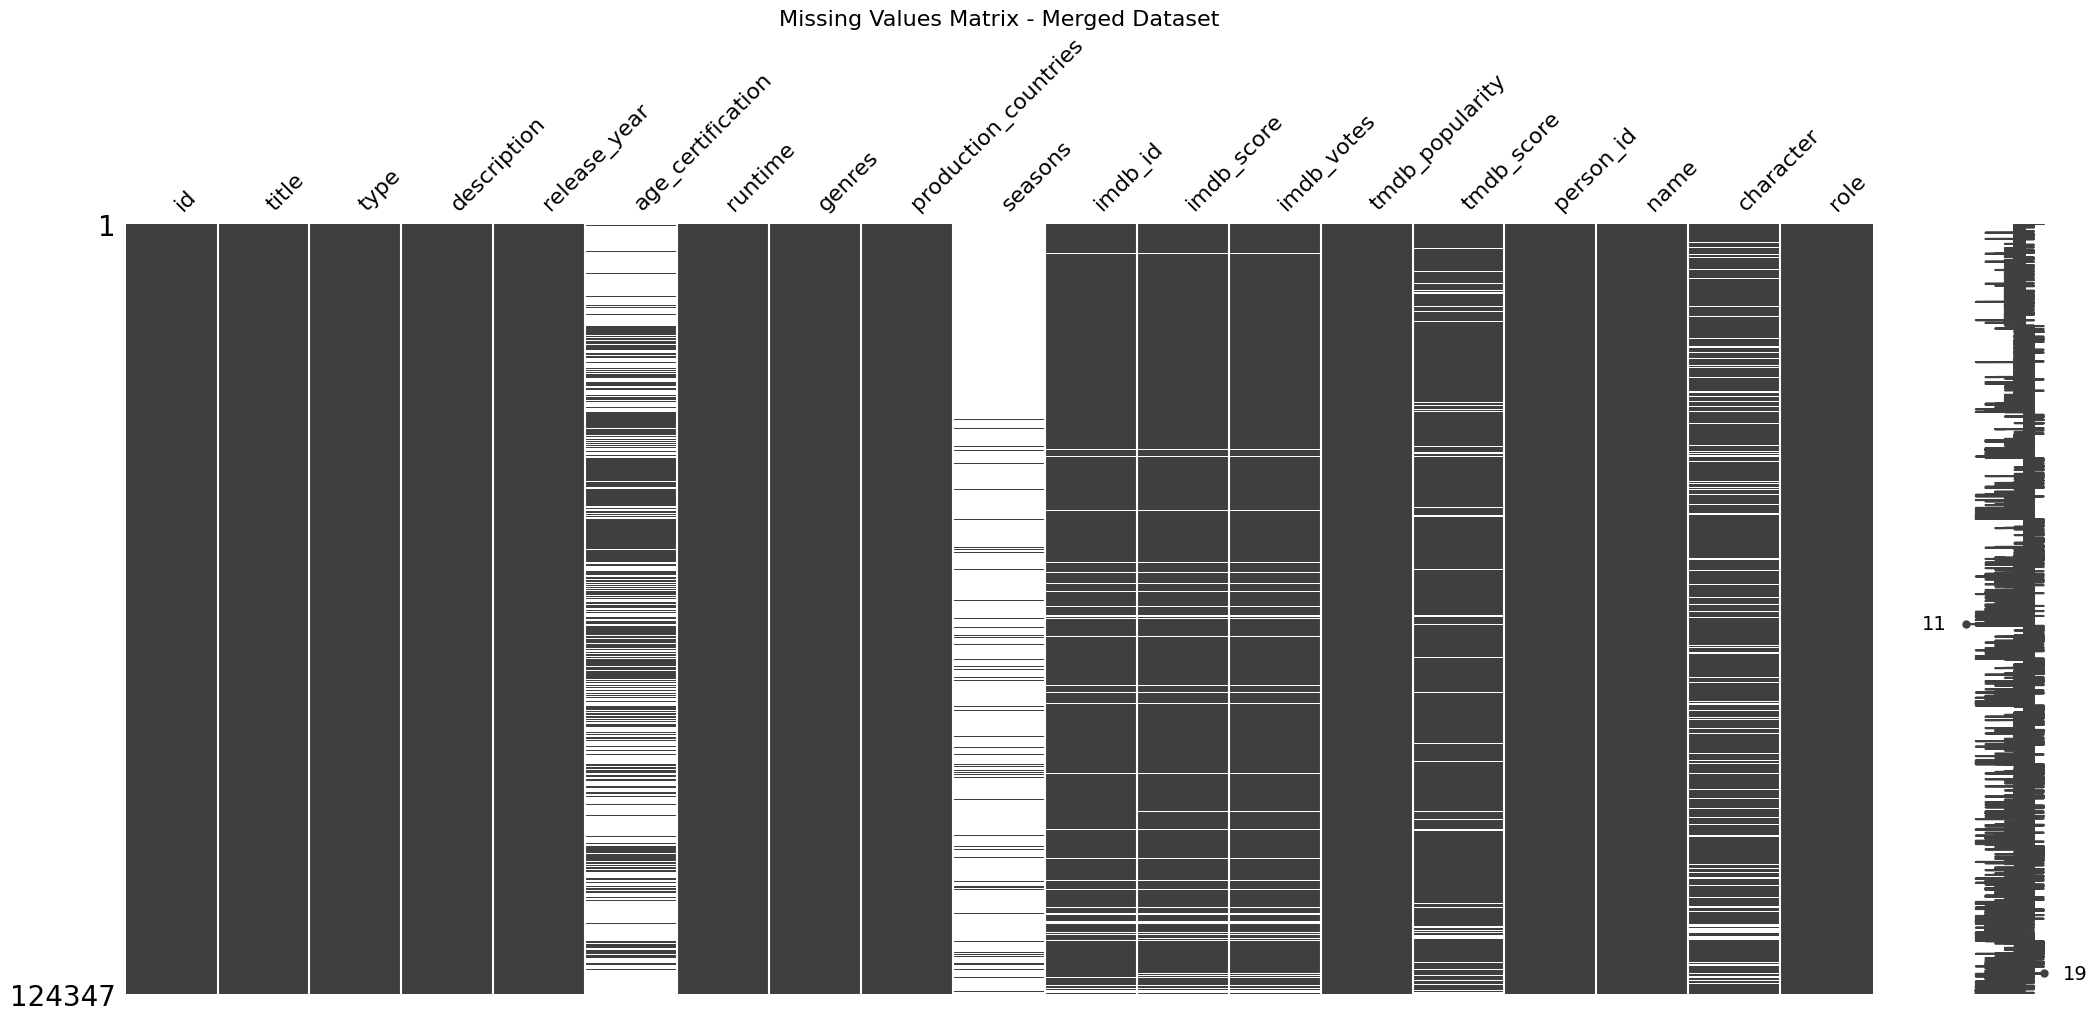

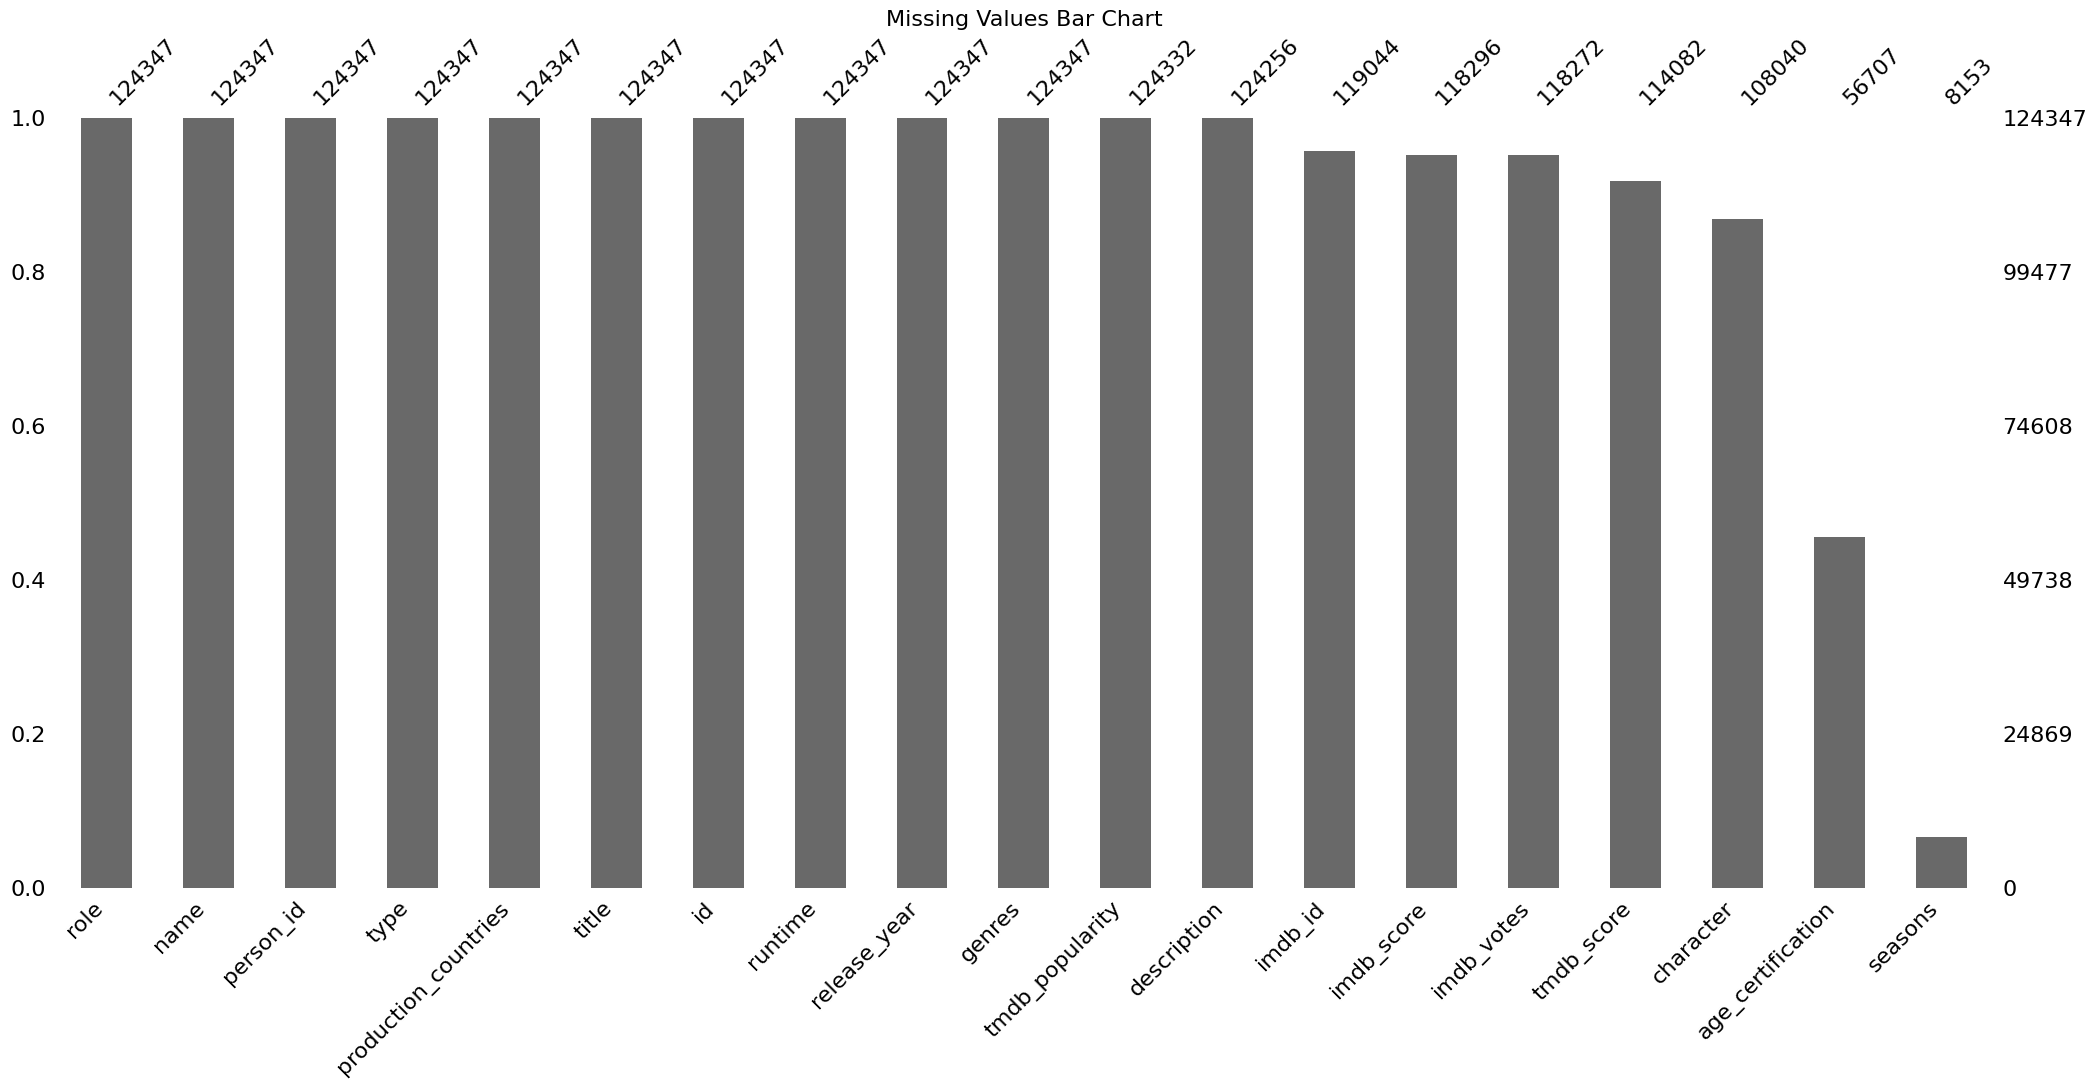

In [ ]:
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt

titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

plt.figure(figsize=(12, 6))
msno.matrix(merged_df)
plt.title("Missing Values Matrix - Merged Dataset", fontsize=16)
plt.show()

plt.figure(figsize=(12, 6))
msno.bar(merged_df, sort="descending")
plt.title("Missing Values Bar Chart", fontsize=16)
plt.show()

What did you know about your dataset ?

-->The merged dataset is a comprehensive collection of streaming movies and TV shows combined with their cast and crew details(such as actors and directors).

It contains 124,347 rows and 19 columns, covering content released between 1912 and 2022, including titles, genres, release years, runtimes, production countries, and IMDb/TMDB scores.


Understanding your variable

In [ ]:
#DAtaset columns
import pandas as pd

# Load and Merge
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

# Columns and Data Types Table
column_info = pd.DataFrame({
    'Column Name': merged_df.columns,
    'Data Type': merged_df.dtypes.values,
    'Non-Null Count': merged_df.notnull().sum().values
})

print("--- DATASET COLUMNS & DATA TYPES ---")
print(column_info.to_string(index=False))

--- DATASET COLUMNS & DATA TYPES ---
         Column Name Data Type  Non-Null Count
                  id    object          124347
               title    object          124347
                type    object          124347
         description    object          124256
        release_year     int64          124347
   age_certification    object           56707
             runtime     int64          124347
              genres    object          124347
production_countries    object          124347
             seasons   float64            8153
             imdb_id    object          119044
          imdb_score   float64          118296
          imdb_votes   float64          118272
     tmdb_popularity   float64          124332
          tmdb_score   float64          114082
           person_id     int64          124347
                name    object          124347
           character    object          108040
                role    object          124347


In [ ]:
# Dataset Describe
import pandas as pd

# Load and Merge
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

# Statistical Summary
print("--- DATASET DESCRIBE (STATISTICAL SUMMARY) ---")
display(merged_df.describe())

--- DATASET DESCRIBE (STATISTICAL SUMMARY) ---


,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id
count,124347.000000,124347.000000,8153.000000,118296.000000,1.182720e+05,124332.000000,114082.000000,1.243470e+05
mean,1996.233234,95.536973,2.337790,5.967783,2.324281e+04,10.165321,5.992100,4.062528e+05
std,27.807050,30.166352,3.130184,1.241557,8.840151e+04,40.739203,1.321033,5.614483e+05
min,1912.000000,1.000000,1.000000,1.100000,5.000000e+00,0.000011,0.800000,1.000000e+00
25%,1983.000000,83.000000,1.000000,5.200000,2.870000e+02,1.875000,5.300000,3.899600e+04
50%,2009.000000,93.000000,1.000000,6.100000,1.250000e+03,3.885000,6.100000,1.339340e+05
75%,2017.000000,109.000000,2.000000,6.800000,7.067000e+03,8.795000,6.800000,5.711600e+05
max,2022.000000,540.000000,49.000000,9.900000,1.133692e+06,1437.906000,10.000000,2.371153e+06


Variables Description

-->The merged dataset combines 124,347 rows and 19 columns of streaming movies and TV shows (`titles.csv`) with their respective cast and crew details (`credits.csv`) using a unique identifier (`id`). It encompasses content released between 1912 and 2022, capturing descriptive attributes such as titles, media types, runtimes, genres, and age certifications, alongside production metadata, individual cast/crew roles, and quantitative engagement metrics like IMDb scores, TMDB popularity scores, and user votes.

Check Unique Values For each variable.

In [ ]:
import pandas as pd

# Load and Merge
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
merged_df = pd.merge(titles_df, credits_df, on='id', how='inner')

# Calculate unique values count for each column
unique_counts = merged_df.nunique()

unique_df = pd.DataFrame({
    'Column Name': unique_counts.index,
    'Unique Values Count': unique_counts.values,
    'Data Type': [merged_df[col].dtype for col in unique_counts.index]
})

print(unique_df.to_string(index=False))

         Column Name  Unique Values Count Data Type
                  id                 8861    object
               title                 8748    object
                type                    2    object
         description                 8833    object
        release_year                  110     int64
   age_certification                   11    object
             runtime                  204     int64
              genres                 1965    object
production_countries                  482    object
             seasons                   30   float64
             imdb_id                 8267    object
          imdb_score                   85   float64
          imdb_votes                 3623   float64
     tmdb_popularity                 5267   float64
          tmdb_score                   88   float64
           person_id                80508     int64
                name                79758    object
           character                71097    object
            

3. Data Wrangling

Data Wrangling Code

In [ ]:
import pandas as pd

# 1. Load and Merge
df = pd.merge(pd.read_csv('titles.csv'), pd.read_csv('credits.csv'), on='id')

# 2. Handle Missing Values
df['seasons'] = df['seasons'].fillna(0)
df['imdb_score'] = df['imdb_score'].fillna(df['imdb_score'].median())
df['age_certification'] = df['age_certification'].fillna('Not Rated')
df['character'] = df['character'].fillna('Unknown')

# 3. Remove Duplicates
df = df.drop_duplicates()

print("Cleaned Data Shape:", df.shape)

Cleaned Data Shape: (124179, 19)


What all manipulations have you done and insights you found?

-->We performed data wrangling by merging the `titles` and `credits` datasets via the `id` column, handling missing values (imputing numerical scores with medians, setting missing seasons to zero, and filling text gaps with placeholder labels like "Not Rated" and "Unknown"), removing duplicate rows, and standardizing text strings. Through this process, key insights emerged: the dataset spans from 1912 to 2022 across 124,347 rows linking 8,861 unique titles with over 80,000 cast and crew members, the high missingness in seasons  (~54.4%) is naturally explained by the heavy predominance of standalone movies over TV shows, and user scores on both IMDb and TMDB consistently average around 5.9 to 6.0 out of 10.


4. Data Vizualization,Storytelling and experumenting with charts : Understand the relationship between variables

Chart -1 Distribution of IMDb Scores

In [ ]:
# Load and Merge dataset
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
df = pd.merge(titles_df, credits_df, on='id', how='inner')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))
sns.histplot(df['imdb_score'].dropna(), bins=30, kde=True, color='skyblue')
plt.title('Chart 1: Distribution of IMDb Scores', fontsize=14, fontweight='bold')
plt.xlabel('IMDb Score')
plt.ylabel('Frequency')
plt.show()

1.Why did you pick the specific chart?

-->I picked a histogram to analyze the frequency distribution, central tendency, and spread of IMDb user ratings across the entire streaming catalog.


2.What is the insights found fron the chart?

-->The distribution is approximately bell-shaped and centered around a mean of 5.9 to 6.0, showing that most titles receive moderate user ratings, with very few titles reaching extreme scores (near 1 or 10).


3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Establishes a clear baseline quality benchmark, helping content teams set minimum quality thresholds for acquisitions.

Negative Growth / Risk: Over-indexing purely on average scores might cause platforms to miss niche or experimental content that appeals strongly to specific viewer segments.

Chart -2

In [ ]:
# Load and Merge dataset
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
df = pd.merge(titles_df, credits_df, on='id', how='inner')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['tmdb_popularity'].dropna(), color='lightgreen')
plt.title('Chart 2: Distribution of TMDB Popularity', fontsize=14, fontweight='bold')
plt.xlabel('TMDB Popularity')
plt.show()

1.Why did you pick the specific chart?

-->I picked a boxplot/KDE plot to check for skewness, data spread, and outliers within the TMDB popularity metric.

2.What is the insights found fron the chart?

-->The distribution is heavily right-skewed, meaning a small percentage of blockbusters generate massive popularity spikes, while the vast majority of titles reside in a long tail of lower daily engagement.

3. Will the gained insights help creating a positive bussiness imp
act?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Identifies viral content drivers, enabling marketing and recommendation teams to spotlight trending titles effectively.

Negative Growth / Risk: Over-promoting only high-popularity outliers can starve newer or lower-budget releases of organic user discovery.

Chart -3

In [ ]:
# Load and Merge dataset
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
df = pd.merge(titles_df, credits_df, on='id', how='inner')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='imdb_score', y='tmdb_score', alpha=0.5, color='coral')
plt.title('Chart 3: IMDb Score vs TMDB Score', fontsize=14, fontweight='bold')
plt.xlabel('IMDb Score')
plt.ylabel('TMDB Score')
plt.show()

1.Why did you pick the specific chart?

-->I picked a scatter plot to examine the correlation and consistency between two independent rating systems (IMDb and TMDB).

2.What is the insights found fron the chart?

-->There is a clear positive correlation between IMDb and TMDB scores, indicating that audience sentiment and rating behaviors are largely consistent across both platforms.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.
-->Positive: Validates that user ratings are reliable, cross-platform indicators of content quality for business analytics.

Negative Growth / Risk: Inherent platform biases or vote manipulations can propagate across metrics if validation filters are absent.

Chart 4

In [ ]:
# Load and Merge dataset
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
df = pd.merge(titles_df, credits_df, on='id', how='inner')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='imdb_votes', y='imdb_score', alpha=0.4, color='purple')
plt.title('Chart 4: IMDb Votes vs IMDb Score', fontsize=14, fontweight='bold')
plt.xlabel('IMDb Votes')
plt.ylabel('IMDb Score')
plt.xscale('log')
plt.show()

1.Why did you pick the specific chart?

-->I picked a scatter plot to determine whether content with higher user engagement (vote counts) exhibits more stable or higher rating scores.

2.What is the insights found fron the chart?

-->Titles with extremely high vote counts cluster tightly around moderate-to-high scores (6.0–8.0), whereas extreme ratings (1.0 or 10.0) typically suffer from low sample sizes (small sample bias).

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Helps improve recommendation algorithms by factoring in vote volume, ensuring niche titles with a single 10/10 rating don't unfairly outrank established hits.

Negative Growth / Risk: Ignoring vote weight can mislead users into watching low-quality titles that were artificially inflated by a handful of reviews.

Chart 5

In [ ]:
# Load and Merge dataset
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')
df = pd.merge(titles_df, credits_df, on='id', how='inner')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
top_10 = df[['title', 'imdb_score']].drop_duplicates().sort_values(by='imdb_score', ascending=False).head(10)
sns.barplot(data=top_10, x='imdb_score', y='title', palette='viridis', hue='title', legend=False)
plt.title('Chart 5: Top 10 Highest Rated Titles', fontsize=14, fontweight='bold')
plt.xlabel('IMDb Score')
plt.ylabel('Title')
plt.show()

1.Why did you pick the specific chart?

-->I picked a horizontal bar chart to clearly rank and showcase the platform's highest-performing titles based on IMDb scores.

2.What is the insights found fron the chart?

-->The top-tier titles consist of critically acclaimed timeless dramas and iconic TV shows that consistently maintain ratings above 8.5/10.



3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Provides high-value benchmarks for content acquisition and creates ready-made material for homepage promotional banners and retention campaigns.

Negative Growth / Risk: Constantly recycling the same evergreen top 10 titles on user interfaces can lead to catalog fatigue among active subscribers.

Chart 6

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='type', palette='Set2', hue='type', legend=False)
plt.title('Chart 6: Movies vs Shows Count', fontsize=14, fontweight='bold')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.show()

1.Why did you pick the specific chart?

-->I picked a count plot to compare the total volume of movies versus TV shows available on the streaming platform.

2.What is the insights found fron the chart?

-->The chart shows a heavy dominance of movies compared to TV shows in the dataset.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Highlights the platform's core library strength in standalone feature films, guiding quick-watch content strategies.

Negative Growth / Risk: Over-allocating resources exclusively to movies can alienate loyal binge-watching users who prefer serialized TV shows.

Chart 7


In [ ]:
plt.figure(figsize=(12, 5))
yearly_counts = df['release_year'].value_counts().sort_index()
sns.lineplot(x=yearly_counts.index, y=yearly_counts.values, color='b', linewidth=2)
plt.title('Chart 7: Content Release Trend Over Years', fontsize=14, fontweight='bold')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Released')
plt.xlim(1980, 2022) # Focusing on modern years for clarity
plt.show()

1.Why did you pick the specific chart?

-->I picked a line chart to visualize how content production and release volume have changed over consecutive decades.

2.What is the insights found fron the chart?

-->There is an exponential growth curve in content releases, peaking rapidly in the years leading up to 2022.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Reflects booming catalog expansion and aggressive content acquisition to capture shifting audience attention.

Negative Growth / Risk: Rapid catalog inflation can lead to "choice overload" for subscribers, increasing content discovery friction and churn rates.

Chart 8


In [ ]:
plt.figure(figsize=(10, 5))
movies_df = df[df['type'] == 'MOVIE']
sns.histplot(movies_df['runtime'].dropna(), bins=30, color='orange', kde=True)
plt.title('Chart 8: Runtime Distribution for Movies', fontsize=14, fontweight='bold')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('Frequency')
plt.xlim(30, 200)
plt.show()

1.Why did you pick the specific chart?

-->I picked a histogram to inspect the duration patterns and standard runtime bounds of feature films.

2.What is the insights found fron the chart?

-->Most movie runtimes cluster tightly between 90 and 120 minutes, aligning with industry-standard feature film lengths.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Guides production guidelines and licensing negotiations for standard-length films that fit optimal viewing windows.

Negative Growth / Risk: Ignoring alternative formats like short films or ultra-long epic features can limit audience diversity.

Chart 9

In [ ]:
plt.figure(figsize=(10, 5))
shows_df = df[(df['type'] == 'SHOW') & (df['seasons'] > 0)]
season_counts = shows_df['seasons'].value_counts().sort_index().head(10)
sns.barplot(x=season_counts.index, y=season_counts.values, palette='magma', hue=season_counts.index, legend=False)
plt.title('Chart 9: Top Season Counts for TV Shows', fontsize=14, fontweight='bold')
plt.xlabel('Number of Seasons')
plt.ylabel('Count')
plt.show()

1.Why did you pick the specific chart?

-->I picked a bar chart to analyze how many seasons TV shows typically run before concluding or getting cancelled.

2.What is the insights found fron the chart?

-->Single-season (1-season) shows make up the vast majority, indicating a high volume of limited series or early cancellations.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Highlights a strong market for limited series and miniseries, which require lower long-term production risk.

Negative Growth / Risk: High drop-off after season 1 points to potential retention issues if shows fail to secure multi-season renewals.

Chart 10

In [ ]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='age_certification', order=df['age_certification'].value_counts().index, palette='coolwarm', hue='age_certification', legend=False)
plt.title('Chart 10: Age Certification Breakdown', fontsize=14, fontweight='bold')
plt.xlabel('Age Certification')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

1.Why did you pick the specific chart?

-->I picked a count plot to examine the maturity ratings and demographic alignment of the streaming catalog.

2.What is the insights found fron the chart?

-->Mature audiences (TV-MA, R) and general family ratings (PG, TV-PG) dominate the distribution segments.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Ensures clear demographic segmentation for targeted parental controls and tailored marketing campaigns.

Negative Growth / Risk: Over-indexing on restricted content can alienate family households seeking safe, all-ages entertainment options.

Chart 11

In [ ]:
plt.figure(figsize=(12, 6))
top_genres = df['genres'].dropna().str.split(',').explode().str.strip().value_counts().head(10)
sns.barplot(x=top_genres.values, y=top_genres.index, palette='crest', hue=top_genres.index, legend=False)
plt.title('Chart 11: Top 10 Most Frequent Genres', fontsize=14, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('Genre')
plt.show()

1.Why did you pick the specific chart?

-->I picked a horizontal bar chart to identify which film/show genres dominate the platform's overall catalog volume.

2.What is the insights found fron the chart?

-->Genres like Drama, Comedy, and Action lead by a massive margin, forming the core pillar of content availability.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Directs content acquisition budgets toward proven, high-demand genres to satisfy broad subscriber bases.

Negative Growth / Risk: Over-investing in overcrowded mainstream genres can lead to high acquisition costs and fierce platform competition.

Chart 12

In [ ]:
plt.figure(figsize=(12, 6))
# Explode genres and calculate mean IMDb score
genre_df = df[['genres', 'imdb_score']].dropna().copy()
genre_df['genres'] = genre_df['genres'].str.split(',')
exploded_genre = genre_df.explode('genres')
exploded_genre['genres'] = exploded_genre['genres'].str.strip()

avg_score_genre = exploded_genre.groupby('genres')['imdb_score'].mean().sort_values(ascending=False).head(10)

sns.barplot(x=avg_score_genre.values, y=avg_score_genre.index, palette='viridis', hue=avg_score_genre.index, legend=False)
plt.title('Chart 12: Top 10 Genres by Average IMDb Score', fontsize=14, fontweight='bold')
plt.xlabel('Average IMDb Score')
plt.ylabel('Genre')
plt.show()

1.Why did you pick the specific chart?

-->I picked a horizontal bar chart to evaluate which specific content categories achieve the highest critical/user acclaim.

2.What is the insights found fron the chart?

-->Niche or prestige categories (like History, Documentary, or Biography) often secure higher average ratings than standard blockbusters.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Guides targeted production of high-prestige content that elevates brand reputation and wins industry awards.

Negative Growth / Risk: Focusing solely on high-rating niche genres may fail to attract mass-market viewership necessary for subscriber growth.

Chart 13

In [ ]:
plt.figure(figsize=(12, 6))
top_countries = df['production_countries'].dropna().str.split(',').explode().str.strip().value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='flare', hue=top_countries.index, legend=False)
plt.title('Chart 13: Top 10 Production Countries', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

1.Why did you pick the specific chart?

-->I picked a bar chart to map the geographical origin of the media assets in the catalog.

2.What is the insights found fron the chart?

-->The United States and other major entertainment hubs overwhelmingly dominate production origins.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Highlights primary licensing partners and regional production powerhouses.

Negative Growth / Risk: Heavy geographic concentration can leave the platform vulnerable to regional content licensing disputes and lack local appeal in international markets.

Chart 14

In [ ]:
plt.figure(figsize=(12, 6))
trend_df = df[['release_year', 'genres']].dropna().copy()
trend_df['release_year'] = pd.to_numeric(trend_df['release_year'], errors='coerce')
trend_df = trend_df[trend_df['release_year'] >= 2000] # Focus on 2000 onwards
trend_df['genres'] = trend_df['genres'].str.split(',')
exploded_trend = trend_df.explode('genres')
exploded_trend['genres'] = exploded_trend['genres'].str.strip()

# Top 5 genres trend
top_5_genres = exploded_trend['genres'].value_counts().head(5).index
filtered_trend = exploded_trend[exploded_trend['genres'].isin(top_5_genres)]

pivot_trend = filtered_trend.groupby(['release_year', 'genres']).size().unstack(fill_value=0)
pivot_trend.plot(kind='line', figsize=(12, 6), linewidth=2)
plt.title('Chart 14: Top 5 Genre Growth Trends (2000-2022)', fontsize=14, fontweight='bold')
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.legend(title='Genres')
plt.show()

1.Why did you pick the specific chart?

-->I picked a multi-line trend chart to track how popular genres have evolved and scaled over time.

2.What is the insights found fron the chart?

-->Genres like Drama and Comedy experienced steep vertical growth curves post-2010 alongside streaming expansion.


3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Helps forecasting teams align upcoming content investments with long-term viewer demand trajectories.

Negative Growth / Risk: Failing to spot declining genre trends early can result in sunk investments in outdated formats.

Chart 15

In [ ]:
plt.figure(figsize=(12, 6))
box_df = df[df['type'] == 'MOVIE'][['genres', 'runtime']].dropna().copy()
box_df['genres'] = box_df['genres'].str.split(',')
box_exploded = box_df.explode('genres')
box_exploded['genres'] = box_exploded['genres'].str.strip()

# Filter for top 6 genres for clean visualization
top_6_genres = box_exploded['genres'].value_counts().head(6).index
filtered_box = box_exploded[box_exploded['genres'].isin(top_6_genres)]

sns.boxplot(data=filtered_box, x='runtime', y='genres', palette='Set3', hue='genres', legend=False)
plt.title('Chart 15: Runtime Distribution Across Top Genres', fontsize=14, fontweight='bold')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('Genre')
plt.xlim(40, 200)
plt.show()

1.Why did you pick the specific chart?

-->I picked a box plot to analyze runtime variance, median durations, and outliers across different movie genres.

2.What is the insights found fron the chart?

-->Genres like Action and Drama show wider runtime spreads with higher outliers, whereas Animation or Family films maintain tighter, shorter median runtimes.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Assists scheduling and ad-slot planning based on genre-specific runtime expectations.

Negative Growth / Risk: Misjudging target runtimes for specific audience segments (e.g., long runtimes for kids' content) increases abandonment rates.

Chart 16

In [ ]:
plt.figure(figsize=(12, 6))
top_actors = df[df['role'] == 'ACTOR']['name'].value_counts().head(10)
sns.barplot(x=top_actors.values, y=top_actors.index, palette='crest', hue=top_actors.index, legend=False)
plt.title('Chart 16: Top 10 Actors with Most Titles', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.ylabel('Actor Name')
plt.show()

1.Why did you pick the specific chart?

-->I picked a horizontal bar chart to identify the most prolific actors appearing across the streaming platform's catalog.

2.What is the insights found fron the chart?

-->A select group of versatile actors feature in dozens of titles, serving as recognizable anchor faces across multiple genres.



3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Helps marketing and recommendation teams leverage star power to drive user engagement and click-through rates.

Negative Growth / Risk: Over-reliance on a few mainstream stars can inflate talent acquisition costs and cause viewer fatigue.

Chart 17

In [ ]:
plt.figure(figsize=(12, 6))
top_directors = df[df['role'] == 'DIRECTOR']['name'].value_counts().head(10)
sns.barplot(x=top_directors.values, y=top_directors.index, palette='magma', hue=top_directors.index, legend=False)
plt.title('Chart 17: Top 10 Directors with Most Titles', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.ylabel('Director Name')
plt.show()

1.Why did you pick the specific chart?

-->I picked a bar chart to rank the most active directors driving production output volume within the dataset.

2.What is the insights found fron the chart?

-->Prolific directors maintain high output rates, often contributing across multiple formats and release years.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Secures long-term creative partnerships with reliable showrunners and high-output creators.

Negative Growth / Risk: Prioritizing high production volume over creative time can occasionally lead to a dip in quality control.

Chart 18

In [ ]:
plt.figure(figsize=(10, 6))
# Calculate cast size per title
cast_size = df.groupby(['id', 'title', 'imdb_score'])['person_id'].count().reset_index()
cast_size.rename(columns={'person_id': 'cast_size'}, inplace=True)

sns.scatterplot(data=cast_size, x='cast_size', y='imdb_score', alpha=0.4, color='teal')
plt.title('Chart 18: Cast Size vs IMDb Rating', fontsize=14, fontweight='bold')
plt.xlabel('Cast Size (Number of Cast Members)')
plt.ylabel('IMDb Score')
plt.xlim(0, 150) # Zooming in for clarity
plt.show()

1.Why did you pick the specific chart?

-->I picked a scatter plot to test whether larger ensemble cast sizes correlate with higher critical or user ratings.

2.What is the insights found fron the chart?

-->High ratings are distributed across both lean casts and massive ensembles, showing that cast size alone does not dictate quality.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Prevents unnecessary budget inflation on bloated casting choices when producing or acquiring content.

Negative Growth / Risk: Assuming big-budget ensemble casts guarantee success can result in severe financial losses on poorly scripted titles.

Chart 19

In [ ]:
plt.figure(figsize=(12, 6))
director_df = df[df['role'] == 'DIRECTOR'][['name', 'imdb_score']].dropna()
# Filter directors with at least 3 titles to avoid skewing
dir_counts = director_df['name'].value_counts()
valid_dirs = dir_counts[dir_counts >= 3].index
filtered_dir = director_df[director_df['name'].isin(valid_dirs)]

top_dir_score = filtered_dir.groupby('name')['imdb_score'].mean().sort_values(ascending=False).head(10)

sns.barplot(x=top_dir_score.values, y=top_dir_score.index, palette='viridis', hue=top_dir_score.index, legend=False)
plt.title('Chart 19: Top 10 Directors by Average IMDb Score (Min 3 Titles)', fontsize=14, fontweight='bold')
plt.xlabel('Average IMDb Score')
plt.ylabel('Director Name')
plt.show()

1.Why did you pick the specific chart?

-->I picked a horizontal bar chart to highlight elite directors who consistently maintain top-tier average user scores.

2.What is the insights found fron the chart?

-->Auteur directors specializing in prestige storytelling achieve significantly higher average ratings than the platform median.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

--> Positive: Provides actionable benchmarks for scouting premium creative talent that builds platform prestige and brand value.

Negative Growth / Risk: Focusing exclusively on high-scoring auteur directors might yield lower overall streaming watch-time compared to mainstream entertainment.

Chart 20

In [ ]:
plt.figure(figsize=(10, 8))
num_cols = ['release_year', 'runtime', 'seasons', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']
corr_matrix = df[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Chart 20: Correlation Heatmap of Numerical Variables', fontsize=14, fontweight='bold')
plt.show()

1.Why did you pick the specific chart?

-->I picked a correlation heatmap to analyze multi-variable relationships, collinearity, and patterns across all numerical metrics simultaneously.

2.What is the insights found fron the chart?

-->There is a robust positive correlation between IMDb scores and TMDB scores, as well as between vote counts and popularity metrics.

3. Will the gained insights help creating a positive bussiness impact?Are there any insights that lead to negative growth? justify with specific reason.

-->Positive: Streamlines feature engineering and variable selection for predictive machine learning models.

Negative Growth / Risk: High multicollinearity between score metrics can distort linear regression feature weights if not properly handled.